# Noise Investigation: Effect of Noisy Training Data on Machine Learning Generalization

**Dataset:** HTRU2 pulsar classification dataset  
**Models:** Logistic Regression and K-Nearest Neighbors (KNN)

## Research Question and Experimental Scope

**Research question:** How does noisy training data affect machine learning generalization?

Two forms of training-data corruption are investigated:

- **Feature noise:** zero-mean Gaussian perturbations added to the training features, with perturbation scale defined relative to each feature's standard deviation.
- **Label noise:** symmetric label flipping applied to training labels, with equal numbers of 0→1 and 1→0 flips so that the training class counts remain unchanged.

The tested feature-noise levels are **0%, 2%, 5%, 10%, 15%, 20%, and 30%**. The tested label-noise levels are **0%, 2%, 4%, 6%, 8%, and 10%**. Each condition is evaluated using **10 repetitions** with different random seeds. The test set remains fixed and clean throughout the experiment.

In [38]:
!pip install ucimlrepo

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [40]:
FIGURES_DIR = Path("figures")
RESULTS_DIR = Path("results")

FIGURES_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42

FEATURE_NOISE_LEVELS = [
    0.00, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30
]

LABEL_NOISE_LEVELS = [
    0.00, 0.02, 0.04, 0.06, 0.08, 0.10
]

N_REPETITIONS = 10
TEST_SIZE = 0.20

In [41]:
htru2 = fetch_ucirepo(id=372)

X = htru2.data.features.copy()
y = htru2.data.targets.copy()

if isinstance(y, pd.DataFrame):
    y = y.iloc[:, 0]

X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

assert not X.isna().any().any()
assert not y.isna().any()
assert set(y.unique()) <= {0, 1}

In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

In [43]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        ))
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ])
}

In [44]:
def add_feature_noise(X_data, noise_level, random_state):
    rng = np.random.default_rng(random_state)
    stds = X_data.std(axis=0).to_numpy()
    noise = rng.normal(
        loc=0,
        scale=noise_level * stds,
        size=X_data.shape
    )
    return pd.DataFrame(
        X_data.to_numpy() + noise,
        columns=X_data.columns,
        index=X_data.index
    )


def add_symmetric_label_noise(y_data, noise_level, random_state):
    rng = np.random.default_rng(random_state)
    y_noisy = y_data.reset_index(drop=True).copy()

    idx0 = np.flatnonzero(y_noisy.to_numpy() == 0)
    idx1 = np.flatnonzero(y_noisy.to_numpy() == 1)

    total = int(round(noise_level * len(y_noisy)))
    n_each = total // 2

    if n_each > min(len(idx0), len(idx1)):
        raise ValueError("Requested symmetric label noise is infeasible.")

    flip0 = rng.choice(idx0, size=n_each, replace=False)
    flip1 = rng.choice(idx1, size=n_each, replace=False)

    y_noisy.iloc[flip0] = 1
    y_noisy.iloc[flip1] = 0

    return y_noisy.astype(int)

In [45]:
def evaluate_model(model, X_train_data, y_train_data, X_test_data, y_test_data):
    model.fit(X_train_data, y_train_data)
    y_pred = model.predict(X_test_data)
    y_prob = model.predict_proba(X_test_data)[:, 1]

    return {
        "Accuracy": accuracy_score(y_test_data, y_pred),
        "Precision": precision_score(y_test_data, y_pred, zero_division=0),
        "Recall": recall_score(y_test_data, y_pred, zero_division=0),
        "F1": f1_score(y_test_data, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test_data, y_prob)
    }


baseline_results = []
for model_name, model in models.items():
    metrics = evaluate_model(model, X_train, y_train, X_test, y_test)
    baseline_results.append({
        "Model": model_name,
        **metrics
    })

baseline_df = pd.DataFrame(baseline_results)
baseline_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.979609,0.944251,0.826220,0.881301,0.970987
1,KNN,0.980447,0.932886,0.847561,0.888179,0.951616


In [46]:
def run_noise_experiment(
    noise_levels,
    noise_function,
    noise_type,
    X_train_data,
    y_train_data,
    X_test_data,
    y_test_data,
    models_dict,
    n_repetitions,
    random_state
):
    rows = []
    for noise_level in noise_levels:
        for repetition in range(n_repetitions):
            seed = random_state + repetition + int(noise_level * 10000)

            if noise_type == "Feature":
                X_noisy = noise_function(X_train_data, noise_level, seed)
                y_noisy = y_train_data
            else:
                X_noisy = X_train_data
                y_noisy = noise_function(y_train_data, noise_level, seed)

            for model_name, model in models_dict.items():
                metrics = evaluate_model(model, X_noisy, y_noisy, X_test_data, y_test_data)
                rows.append({
                    "Noise_Type": noise_type,
                    "Noise_Level": noise_level,
                    "Repetition": repetition + 1,
                    "Model": model_name,
                    **metrics
                })
    return pd.DataFrame(rows)


feature_results = run_noise_experiment(
    FEATURE_NOISE_LEVELS,
    add_feature_noise,
    "Feature",
    X_train,
    y_train,
    X_test,
    y_test,
    models,
    N_REPETITIONS,
    RANDOM_STATE
)

label_results = run_noise_experiment(
    LABEL_NOISE_LEVELS,
    add_symmetric_label_noise,
    "Label",
    X_train,
    y_train,
    X_test,
    y_test,
    models,
    N_REPETITIONS,
    RANDOM_STATE
)

results = pd.concat([feature_results, label_results], ignore_index=True)
results

,Noise_Type,Noise_Level,Repetition,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Feature,0.0,1,Logistic Regression,0.979609,0.944251,0.826220,0.881301,0.970987
1,Feature,0.0,1,KNN,0.980447,0.932886,0.847561,0.888179,0.951616
2,Feature,0.0,2,Logistic Regression,0.979609,0.944251,0.826220,0.881301,0.970987
3,Feature,0.0,2,KNN,0.980447,0.932886,0.847561,0.888179,0.951616
4,Feature,0.0,3,Logistic Regression,0.979609,0.944251,0.826220,0.881301,0.970987
...,...,...,...,...,...,...,...,...,...
255,Label,0.1,8,KNN,0.934916,0.886179,0.332317,0.483370,0.856162
256,Label,0.1,9,Logistic Regression,0.926257,1.000000,0.195122,0.326531,0.972259
257,Label,0.1,9,KNN,0.934916,0.892562,0.329268,0.481069,0.880169
258,Label,0.1,10,Logistic Regression,0.930726,1.000000,0.243902,0.392157,0.971663


In [47]:
summary = (
    results
    .groupby(["Noise_Type", "Noise_Level", "Model"])
    .agg(
        F1_Mean=("F1", "mean"),
        F1_SD=("F1", "std"),
        ROC_AUC_Mean=("ROC-AUC", "mean"),
        ROC_AUC_SD=("ROC-AUC", "std")
    )
    .reset_index()
)

baseline_f1 = baseline_df[["Model", "F1"]].rename(columns={"F1": "Baseline_F1"})
degradation = summary.merge(baseline_f1, on="Model", how="left")
degradation["F1_Degradation_Percent"] = (
    (degradation["Baseline_F1"] - degradation["F1_Mean"])
    / degradation["Baseline_F1"]
    * 100
)

degradation

,Noise_Type,Noise_Level,Model,F1_Mean,F1_SD,ROC_AUC_Mean,ROC_AUC_SD,Baseline_F1,F1_Degradation_Percent
0,Feature,0.00,KNN,0.888179,0.000000,0.951616,0.000000,0.888179,0.000000e+00
1,Feature,0.00,Logistic Regression,0.881301,0.000000,0.970987,0.000000,0.881301,1.259755e-14
2,Feature,0.02,KNN,0.888672,0.002451,0.951205,0.001373,0.888179,-5.553268e-02
3,Feature,0.02,Logistic Regression,0.880390,0.000960,0.971080,0.000078,0.881301,1.033691e-01
4,Feature,0.05,KNN,0.888996,0.002781,0.951001,0.002254,0.888179,-9.199669e-02
5,Feature,0.05,Logistic Regression,0.878351,0.001232,0.971006,0.000179,0.881301,3.347169e-01
6,Feature,0.10,KNN,0.886572,0.004669,0.949802,0.003097,0.888179,1.809478e-01
7,Feature,0.10,Logistic Regression,0.879487,0.001467,0.970700,0.000463,0.881301,2.057705e-01
8,Feature,0.15,KNN,0.881820,0.004927,0.947013,0.002110,0.888179,7.159766e-01
9,Feature,0.15,Logistic Regression,0.876978,0.001970,0.970514,0.000434,0.881301,4.904999e-01


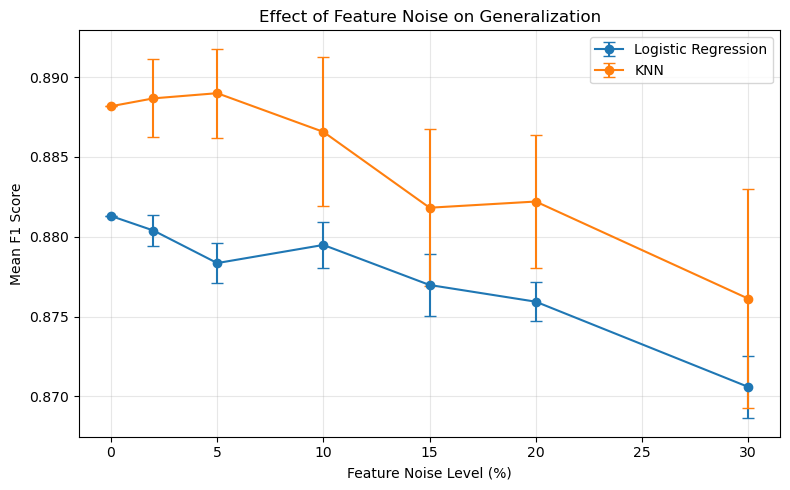

In [48]:
feature_summary = summary[summary["Noise_Type"] == "Feature"]

plt.figure(figsize=(8, 5))
for model_name in models.keys():
    data = feature_summary[feature_summary["Model"] == model_name].sort_values("Noise_Level")
    plt.errorbar(
        data["Noise_Level"] * 100,
        data["F1_Mean"],
        yerr=data["F1_SD"],
        marker="o",
        capsize=4,
        label=model_name
    )

plt.xlabel("Feature Noise Level (%)")
plt.ylabel("Mean F1 Score")
plt.title("Effect of Feature Noise on Generalization")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_noise_f1.png", dpi=300)
plt.show()

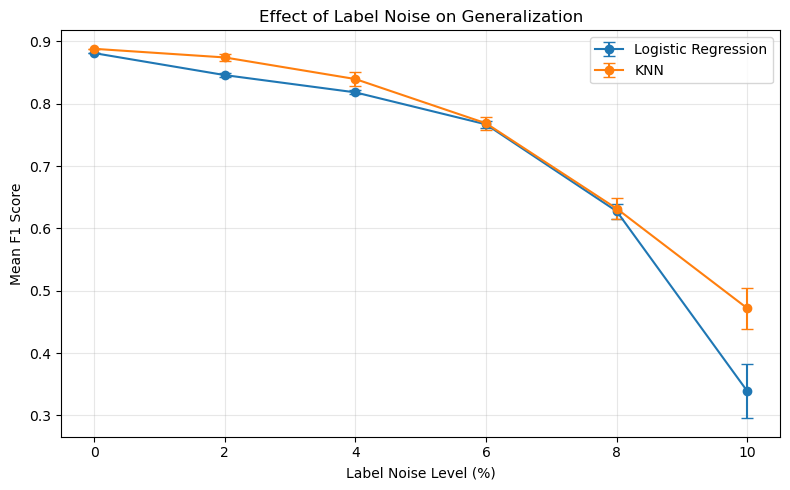

In [49]:
label_summary = summary[summary["Noise_Type"] == "Label"]

plt.figure(figsize=(8, 5))
for model_name in models.keys():
    data = label_summary[label_summary["Model"] == model_name].sort_values("Noise_Level")
    plt.errorbar(
        data["Noise_Level"] * 100,
        data["F1_Mean"],
        yerr=data["F1_SD"],
        marker="o",
        capsize=4,
        label=model_name
    )

plt.xlabel("Label Noise Level (%)")
plt.ylabel("Mean F1 Score")
plt.title("Effect of Label Noise on Generalization")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "label_noise_f1.png", dpi=300)
plt.show()

In [50]:
results.to_csv(RESULTS_DIR / "noise_experiment_results.csv", index=False)
summary.to_csv(RESULTS_DIR / "noise_experiment_summary.csv", index=False)
degradation.to_csv(RESULTS_DIR / "noise_degradation.csv", index=False)

print("Experiment complete.")
print(f"Results saved to {RESULTS_DIR}")
print(f"Figures saved to {FIGURES_DIR}")

Experiment complete.
Results saved to results
Figures saved to figures
